In [165]:
import scipy.stats as ss
import numpy as np
import matplotlib.pyplot as plt
import warnings
from functools import partial
import time
from IPython.display import display, clear_output

warnings.filterwarnings("ignore")

## **Procesos Gausianos para SmartExp**

Este notebook tiene como objetivo ilustrar la idea de SmartExp aplicándolo a modelos simples.
Espero después poder aplicarlo a las matrices de Mueller, pero vamos paso a paso...

### **Hipótesis de los procesos gaussianos**

Estuve investigando distintas formas de implementar el algoritmo de SmartExp y me encontré con la idea de usar procesos gaussianos para modelar la función objetivo. 
Lo bueno de los procesos gaussianos es que hacen un modelo probabilístico de la función objetivo, cuantificando la incertidumbre de predicción en cada punto en base a los puntos ya medidos.
La explicación que hago acá es un resumen del capítulo 2.1 del libro [*Gaussian Processes for Machine Learning*](https://gaussianprocess.org/gpml/chapters/RW.pdf) de Rasmussen.

En este notebook voy a suponer un experimento lineal en los parámetros $\mathbf{w}$ (supongamos de $d$ dimensiones), donde las variables de control son $\mathbf{x}$, la cantidad que se mide es $y$ con un ruido gaussiano $\varepsilon$ con media cero y desviación estandar $\sigma_n$, y el modelo es lineal sin ruido

$$y = \mathbf{x}^T \mathbf{w} + \varepsilon = f(\mathbf{x}) + \varepsilon.$$

Si se tienen $n$ mediciones, el set de datos es $\mathcal{D} = \{ \mathbf{y}, X\}$, donde $X$ es una matriz de $n \times d$ donde cada columna es un vector de d dimensiones que representa una medición.
Los procesos gaussianos determinan la distribución de probabilidad de los parámetros dado el set de datos $\mathcal{D}$ a través del teorema de Bayes

$$p(\mathbf{w} | \mathbf{y}, X) = \frac{p(\mathbf{y}, X | \mathbf{w})p(\mathbf{w})}{p(\mathbf{y},X)} \propto p(\mathbf{y}, X | \mathbf{w})p(\mathbf{w}),$$

donde $p(\mathbf{y}, X)$ no depende de $\mathbf{w}$ por lo que se puede ignorar, y $p(\mathbf{w})$ es la distribución a priori de los parámetros (prior).
Para determinar la prior hacemos un guess, decimos que es una gaussiana de $d$ variables con media cero y matriz de covarianza $\Sigma_p$. 

### **Conclusiones de los procesos gaussianos**

Esas fueron básicamente las hipótesis de los procesos gaussianos, y la conclusión a la que llegan es a que

$$p(\mathbf{w} | \mathbf{y}, X) = \mathcal{N}(\bar{\mathbf{w}}, A^{-1}),$$

donde la varianza es

$$A = \sigma_n^{-2} X X^T + \Sigma_p^{-1}$$

y la media

$$\bar{\mathbf{w}} = \sigma_n^{-2} A^{-1}X\mathbf{y}.$$

La idea es que a partir de las mediciones, se puede estimar la media y la varianza de los parámetros, y a partir de eso se puede hacer un muestreo de los parámetros para hacer una predicción del modelo.
De hecho, la probabilidad de obtener un resultado $f_*(\mathbf{x}_*)$ de nuestro modelo dados nuestros datos $\mathcal{D}$ sale de integrar en los parametros $p(f_* | \mathbf{x}_*, \mathbf{y}, X) = \int p(f_* | \mathbf{x}_*, \mathbf{w})p(\mathbf{w}| \mathbf{y}, X) d\mathbf{w}$, y el resultado es otra normal 

$$p(f_* | \mathbf{x}_*, \mathbf{y}, X) = \mathcal{N}(\sigma_n^{-2} \mathbf{x}_*^T A^{-1} X \mathbf{y}, \quad \mathbf{x}_*^T A^{-1}\mathbf{x}_*).$$

### **Lo importante**

Los procesos gaussianos proporcionan una distribución de probabilidad para los parámetros de nuestro modelo, y por lo tanto para las predicciones.
Esto es ideal para SmartExp, ya que podemos usar la varianza de la predicción para decidir qué mediciones hacer a continuación, y es lo que muestro en este notebook.

A continuación defino funciones para calcular el proceso gaussiano, funciones para plotear, y funciones que determinan cuál es el mejor siguiente **x** a medir.

In [206]:
W_NATURE = np.random.random(size=2) * 2 - 1
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))

##### 
# Gaussian process functions
##### 


def model(X: np.ndarray, w: np.ndarray = W_NATURE):
    """
    Model function that computes the output based on input x and weights w.
    """
    return X.T @ w


def measure(X: np.ndarray, w: np.ndarray = W_NATURE, sigma: float = SIGMA, model: callable = model):
    """
    Measure function that computes the output based on input x and weights w,
    adding Gaussian noise.
    """
    if len(X) > 0:
        return model(X, w) + ss.multivariate_normal.rvs(
            mean=np.zeros(X.shape[1]), cov=SIGMA**2 * np.identity(X.shape[1])
        )
    return np.array([])


def generate_1dX(x: np.ndarray, order: int = 2):
    """
    Generate a 1D input array for the model.
    """
    if len(x) == 0:
        return np.array([])
    vectors = [x**i for i in range(order)]
    return np.hstack(vectors).T


def calc_A(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Calculate matrix A
    """
    if len(X) == 0:
        return np.linalg.inv(cov)
    return sigma ** (-2) * X @ X.T + np.linalg.inv(cov)


def get_posterior_dist(
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the posterior distribution of weights w given measurements D={X, y}.
    """
    if len(y) == 0:
        return ss.multivariate_normal(mean=np.zeros(cov.shape[0]), cov=cov)

    assert len(y) == X.shape[1], f"X.shape[1] = {X.shape[1]} != y.shape[0] = {len(y)}"

    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    m = A_inv @ X @ y / sigma**2
    return ss.multivariate_normal(mean=m, cov=A_inv)


def get_pfstar_mean(
    xstar: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the mean prediction of the model at xstar.
    """
    if len(X) == 0:
        return np.repeat(0, xstar.shape[1])
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    vec = A_inv @ X @ y
    return np.dot(xstar.T, vec) / sigma**2


def get_pfstar_var(
    xstar: np.ndarray,
    X: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the variance of the prediction at xstar.
    """
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)

    # Ensure xstar is 2D
    if xstar.ndim == 1:
        xstar = xstar.reshape(1, -1)

    results = np.einsum("ni,ij,jn->n", xstar.T, A_inv, xstar)

    return results


def get_pfstar_dist(
    xstar: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    cov: np.ndarray = COVARIANCE,
    sigma: float = SIGMA,
):
    """
    Get the posterior distribution of weights w given measurements y and a new input xstar.
    """
    m = get_pfstar_mean(xstar, X, y, cov, sigma)
    var = get_pfstar_var(xstar, X, y, cov, sigma)
    return ss.norm(loc=m, scale=var)



In [178]:
######
# Plotting functions
######

def plot_measurements(
    ax: plt.Axes,
):
    pass

def plot_contour2d(
        ax: plt.Axes,
        dist: ss.rv_continuous,
        color: str = "black",
):
    """
    Plot the prior distribution.
    """
    w0, w1 = np.mgrid[-2:2:0.01, -2:2:0.01]
    pos = np.dstack((w0, w1))
    return ax.contour(w0, w1, dist.pdf(pos), levels=2, colors=color)

def plot_prediction(
        ax: plt.Axes,
        X: np.ndarray,
        y: np.ndarray,
        cov: np.ndarray = COVARIANCE,
        w: np.ndarray = W_NATURE,
):
    """
    Plot the uncertainty of the model.
    """
    xstar = np.linspace(0, 1, 100).reshape(-1, 1)
    xstar = generate_1dX(xstar, order=len(w))
    ystar = get_pfstar_mean(xstar, X, y, cov=cov)
    var = get_pfstar_var(xstar, X, cov=cov)
    std = np.sqrt(var)
    x = xstar[1, :]
    ax.plot(x, ystar, color="blue", label="Mean")
    ax.fill_between(
        x,
        ystar - std,
        ystar + std,
        alpha=0.2,
        color="blue",
        label="Confidence Interval",
    )

def plot_real_space(
        ax: plt.Axes,
        X: np.ndarray,
        y: np.ndarray,
        w: np.ndarray = W_NATURE,
):
    xm = generate_1dX(np.linspace(0, 1, 100).reshape(-1, 1), order=len(w))
    means = get_pfstar_mean(xm, X, y)
    vars = get_pfstar_var(xm, X)

    ax.plot(xm[1, :], means, label="mean", color="blue")
    ax.fill_between(
        xm[1, :],
        y1=means - np.sqrt(vars),
        y2=means + np.sqrt(vars),
        label="$\pm \sigma$",
        color="blue",
        alpha=0.2,
    )


def plot_nature(
        ax: plt.Axes,
        model: callable,
        w: np.ndarray = W_NATURE,
):
    """
    Plot the nature function.
    """
    x = np.linspace(0, 1, 100)
    X = generate_1dX(x.reshape(-1, 1), order=len(w))
    y = model(X, w=w)
    ax.plot(x, y, label="Nature", color="black", linestyle="--")



## Funciones SmartExp

Definen cuál es el mejor próximo $\mathbf{x}$ para medir. 
Hay 3 distintas: una elige $\mathbf{x}$ en una grilla, otra random, y otra a partir del proceso gaussiano.

In [197]:
######
# SmartExp functions
######

def update_data(x: np.ndarray, X, y, w: np.ndarray = W_NATURE, sigma: float = SIGMA):
    """
    Update the data with new measurements.
    """
    X_new = generate_1dX(x.reshape(-1, 1), order=len(w))
    y_new = measure(X_new, w=w, sigma=sigma)
    if len(X) == 0:
        return X_new, y_new
    X = np.hstack((X, X_new))
    y = np.hstack((y, y_new))
    return X, y

def gp_suggest(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    xstar = generate_1dX(np.linspace(0, 1, 100).reshape(-1, 1), order=cov.shape[0])
    var = get_pfstar_var(xstar, X, cov=COVARIANCE, sigma=SIGMA)
    xstar = xstar[1, np.argmax(var)]
    return np.array([xstar])

def random_suggest():
    """
    Randomly suggest a new point.
    """
    return np.random.random(size=1)

def grid_suggest(X: np.ndarray, size: int = 10):
    """
    Suggest a new point based on a grid search.
    """
    xstar = np.linspace(0, 1, size).reshape(-1, 1)
    if len(X) > 0:
        xstar = np.linspace(0, 1, size)[len(X[1,:])]
    else:
        xstar = 0
    return np.array([xstar])

## Primer ejemplo

En esta celda se ve el primer ejemplo.
En este caso, es un modelo lineal. 
La línea punteada negra grafica el resultado real del experimento, la azul nuestra mejor aproximación según las mediciones hechas, y las bandas azules grafican la mejor aproximación $\pm \sigma$ según el proceso gaussiano.

El gráfico de la derecha muestra el espacio de parámetros. 
Por un lado grafica curvas de nivel de la prior (gaussiana centrada en cero), y por otro la distribución actualizada según las mediciones (posterior, en rojo). 
El punto azul indica el valor real de los parámetros, y la cruz roja es el mejor guess según las mediciones que hicimos.

Casi al final de la celda están comentadas las líneas
```python
    new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
    #new_x = random_suggest()
    #new_x = grid_suggest(X, size=reps)
    X, y = update_data(new_x, X, y, w=W_NATURE, sigma=SIGMA)
```
que determinan qué método se usa para elegir el próximo $\mathbf{x}$.
Pueden cambiarlo y jugar con eso.


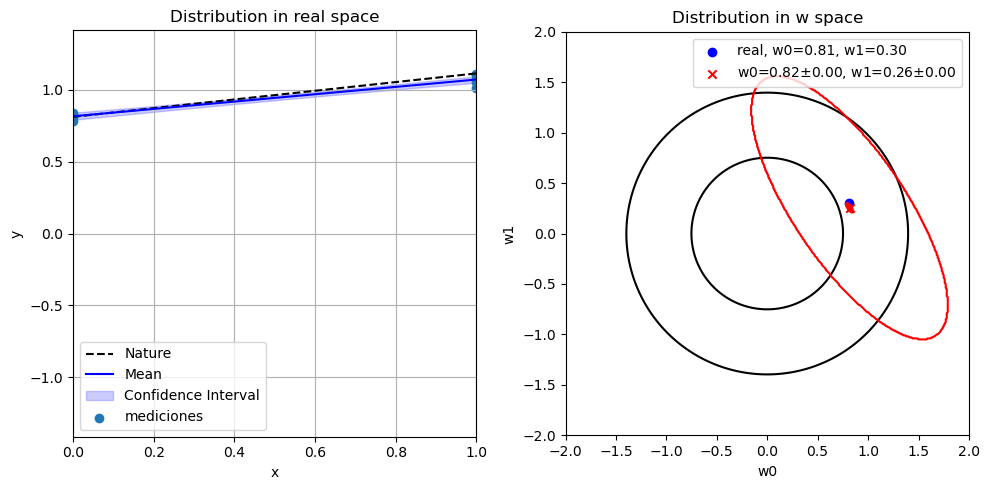

In [ ]:
W_NATURE = np.random.random(size=2) * 2 - 1
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))

X = np.array([]).reshape(-1, 1)
y = np.array([])
reps = 10
for i in range(reps):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # Plot prior
    prior = ss.multivariate_normal(mean=np.zeros(len(W_NATURE)), cov=COVARIANCE)
    plot_contour2d(ax2, prior)

    # Plot real value of the parameters
    ax2.scatter(
        W_NATURE[0],
        W_NATURE[1],
        label=f"real, w0={W_NATURE[0]:.2f}, w1={W_NATURE[1]:.2f}",
        color="blue",
        marker="o",
    )
    plot_nature(ax1, model, w=W_NATURE)

    if len(X) > 0:
        # Compute posterior given measurements and plot
        posterior = get_posterior_dist(X, y)
        plot_contour2d(ax2, posterior, color="red")
    
    # Plot the model's prediction
    plot_prediction(ax1, X, y, cov=COVARIANCE, w=W_NATURE)
    
    # Plot best prediction in w space
    ax2.scatter(
        posterior.mean[0],
        posterior.mean[1],
        label=f"w0={posterior.mean[0]:.2f}$\pm${posterior.cov[0][0]:.2f}, w1={posterior.mean[1]:.2f}$\pm${posterior.cov[1][1]:.2f}",
        color="red",
        marker="x",
    )
    
    # Plot measurements
    if len(X) > 0:
        ax1.scatter(X[1], y, label="mediciones")
    
    
    ax1.set_title("Distribution in real space")
    ax1.set_ylabel("y")
    ax1.set_xlabel("x")
    ax1.set_ylim([-np.sqrt(2), np.sqrt(2)])
    ax1.set_xlim([-0, 1])
    ax1.legend()
    
    ax2.set_ylabel("w1")
    ax2.set_xlabel("w0")
    ax2.set_title("Distribution in w space")
    ax2.set_xlim(-2, 2)
    ax2.set_ylim(-2, 2)
    ax2.set_aspect("equal")
    
    ax1.grid()
    ax2.legend()
    plt.tight_layout()
    fig.show()
    plt.show()
    
    new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
    #new_x = random_suggest()
    #new_x = grid_suggest(X, size=reps)
    X, y = update_data(new_x, X, y, w=W_NATURE, sigma=SIGMA)

    time.sleep(2)
    clear_output(wait=True)

## Segundo ejemplo

Esta celda muestra un ejemplo idéntico al anterior, pero esta vez con un polinomio de grado ```order``` mayor a 1 definido al principio de la celda. 
Aunque los polinomios de mayor orden no sean lineales, igual se pueden modelar con procesos gaussianos porque lo importante es que el modelo sea lineal en los parámetros $\mathbf{w}$. 
Para modelar un polinomio, se cambia el vector $\mathbf{x}$ que mencioné al principio por un vector nuevo

$$\mathbf{x'}^T = (x^0, x^1, ... , x^d),$$

donde $d$ es el grado del polinomio.

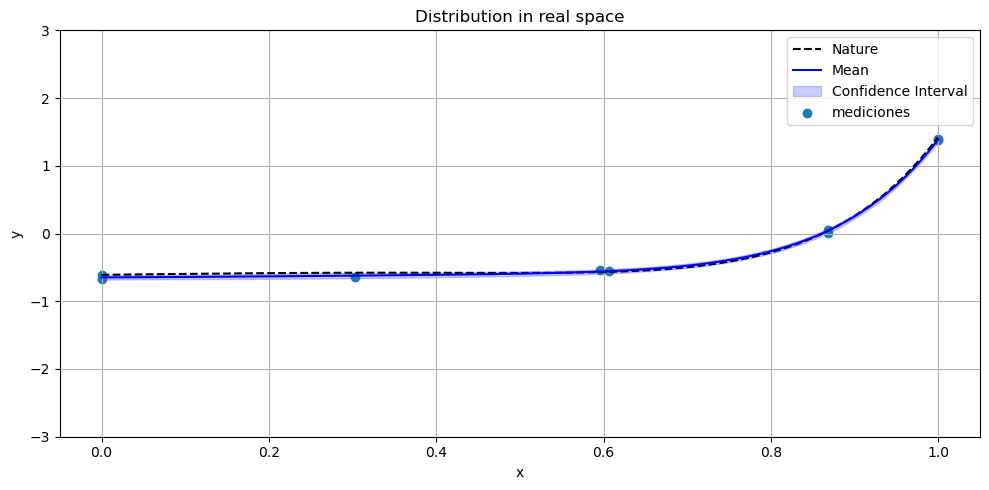

In [269]:
order = 10
W_NATURE = np.random.random(size=order) * 2 - 1
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))


X = np.array([]).reshape(-1, 1)
y = np.array([])
for i in range(10):
    fig, ax = plt.subplots(1, 1, figsize=(10, 5))

    # Plot prior
    prior = ss.multivariate_normal(mean=np.zeros(len(W_NATURE)), cov=COVARIANCE)

    plot_nature(ax, model, w=W_NATURE)

    if len(X) > 0:
        # Compute posterior given measurements and plot
        posterior = get_posterior_dist(X, y, cov=COVARIANCE, sigma=SIGMA)
    
    # Plot the model's prediction
    plot_prediction(ax, X, y, cov=COVARIANCE, w=W_NATURE)
    
    # Plot measurements
    if len(X) > 0:
        ax.scatter(X[1], y, label="mediciones")
    
    
    ax.set_title("Distribution in real space")
    ax.set_ylabel("y")
    ax.set_xlabel("x")
    ax.set_ylim([-3, 3])
    ax.set_xlim([-0.05, 1.05])
    ax.legend()
    
    
    ax.grid()
    plt.tight_layout()
    plt.show()
    
    new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
    #new_x = random_suggest()
    #new_x = grid_suggest(X)
    X, y = update_data(new_x, X, y, w=W_NATURE, sigma=SIGMA)

    time.sleep(2)
    clear_output(wait=True)

## Comparación de suggesters

Acá hago un fit de un polinomio de grado 20 con los distintos suggesters, y en la próxima celda grafico la distancia entre los mejores parámetros adivinados por el fit y los parámetros reales.
Se supone que los procesos gaussianos deberían ser más rápidos...

In [270]:
order = 20
W_NATURE = np.random.random(size=order) * 2 - 1
SIGMA = 0.05
COVARIANCE = np.eye(len(W_NATURE))


suggesters = {
    "gp"    : gp_suggest,
    "random": random_suggest,
    "grid"  : grid_suggest,
}

results = {
    "gp"    : [],
    "random": [],
    "grid"  : [],
}

reps = 10 * len(W_NATURE)
for name, suggester in suggesters.items():
    X = np.array([]).reshape(-1, 1)
    y = np.array([])
    for i in range(reps):

        # Plot prior
        prior = ss.multivariate_normal(mean=np.zeros(len(W_NATURE)), cov=COVARIANCE)

        if len(X) > 0:
            # Compute posterior given measurements and plot
            posterior = get_posterior_dist(X, y, cov=COVARIANCE, sigma=SIGMA)
            results[name].append(np.linalg.norm(posterior.mean - W_NATURE))
        else:
            results[name].append(np.linalg.norm(prior.mean - W_NATURE))

        if name == "gp":
            new_x = gp_suggest(X, cov=COVARIANCE, sigma=SIGMA)
        elif name == "grid":
            new_x = grid_suggest(X, size=reps)
        else:
            new_x = random_suggest()

        X, y = update_data(new_x, X, y, w=W_NATURE, sigma=SIGMA)


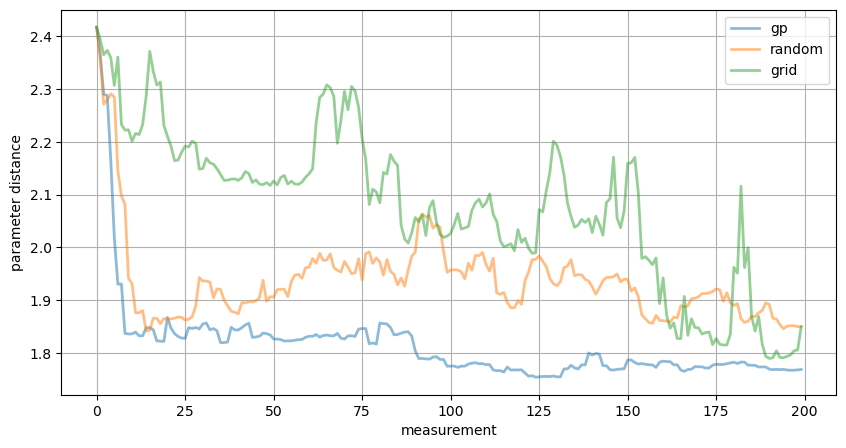

In [271]:
fig, ax = plt.subplots(1, 1, figsize=(10,5), sharey=True)

for name, result in results.items():
    x = np.arange(len(result))
    ax.plot(x, result, '-', label=name, alpha=0.5, linewidth=2)

ax.grid()
ax.legend()
ax.set_xlabel('measurement')
ax.set_ylabel('parameter distance')
plt.show()

Esto es lo que estuve investigando hasta ahora. 
El próximo pasó será intentar aplicarlo a las matrices de Mueller.